## 1. Imports and constants


In [52]:
import os
import joblib
import dtreeviz
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    auc,
    precision_recall_curve,
    log_loss,
    brier_score_loss,
    f1_score,
    precision_score,
    recall_score
)

# Create output directory
os.makedirs('../reports/figures/decision_tree', exist_ok=True)
os.makedirs('../models/decision_tree', exist_ok=True)

def save_fig(name, fig=None):
    """Save figure to reports/figures/decision_tree directory."""
    if fig is None:
        fig = plt.gcf()
    path = f'../reports/figures/decision_tree/{name}.png'
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f'  [saved {path}]')

In [53]:
# Load preprocessed train/test data from 4_preprocessing_imputation.ipynb
X_train = pd.read_csv('../data/weatherAUS_X_train.csv')
X_test = pd.read_csv('../data/weatherAUS_X_test.csv')
y_train = pd.read_csv('../data/weatherAUS_y_train.csv').squeeze()
y_test = pd.read_csv('../data/weatherAUS_y_test.csv').squeeze()

print(f'Loaded preprocessed data:')
print(f'X_train: {X_train.shape}')
print(f'X_test: {X_test.shape}')
print(f'y_train: {y_train.shape}')
print(f'y_test: {y_test.shape}')
print(f'\nData already includes:')
print(f'  - MICE imputation for missing values')
print(f'  - Cyclic encoding of wind directions (sin/cos)')
print(f'  - Categorical encoding (LabelEncoder)')
print(f'  - RobustScaler normalization')
print(f'  - Chronological train/test split (cutoff: 2016-01-01)')

Loaded preprocessed data:
X_train: (113506, 23)
X_test: (25314, 23)
y_train: (113506,)
y_test: (25314,)

Data already includes:
  - MICE imputation for missing values
  - Cyclic encoding of wind directions (sin/cos)
  - Categorical encoding (LabelEncoder)
  - RobustScaler normalization
  - Chronological train/test split (cutoff: 2016-01-01)


In [54]:
# Create and train baseline Decision Tree Classifier
baseline_model = DecisionTreeClassifier(random_state=42, max_depth=5, class_weight='balanced')
baseline_model.fit(X_train, y_train)

# Evaluate on test set
y_pred_test_baseline = baseline_model.predict(X_test)
report_test_baseline = classification_report(y_test, y_pred_test_baseline)

print(f"\n✓ Baseline Model - Test Set Results:")
print(f"\nClassification Report:")
print(report_test_baseline)

joblib.dump(baseline_model, '../models/decision_tree/baseline_decision_tree_model.pkl')


✓ Baseline Model - Test Set Results:

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.78      0.84     19569
           1       0.49      0.73      0.59      5745

    accuracy                           0.77     25314
   macro avg       0.70      0.76      0.72     25314
weighted avg       0.81      0.77      0.78     25314



['../models/decision_tree/baseline_decision_tree_model.pkl']

In [55]:
# Hyperparameter tuning using GridSearchCV on training split only (no leakage).
# Evaluation and test sets remain completely separate.
param_grid = {
    'max_depth': [5, 6, 7, 8, 9],
    'min_samples_split': [9, 10, 11],
    'min_samples_leaf': [3, 4, 5, 6]
}

cv = TimeSeriesSplit(n_splits=5)

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    param_grid=param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

print("Starting GridSearchCV tuning on training split...")
grid_search.fit(X_train, y_train)
print("GridSearchCV complete.")

best_params = grid_search.best_params_
best_score = grid_search.best_score_
print(f"\n🎯 Best hyperparameters: {best_params}")
print(f"Best cross-validation ROC-AUC: {best_score:.4f}")

best_model = grid_search.best_estimator_

# Evaluate best model on test set only (completely unseen)
y_pred_best = best_model.predict(X_test)
y_proba_best = best_model.predict_proba(X_test)[:, 1]

auc_roc_best = roc_auc_score(y_test, y_proba_best)
report_best = classification_report(y_test, y_pred_best, output_dict=True, zero_division=0)

f1_best = report_best['1']['f1-score']
recall_best = report_best['1']['recall']

print(f"\n✓ Best Model - Test Set Performance:")
print(f"AUC-ROC: {auc_roc_best:.4f}")
print(f"F1 Score (Rain=Yes): {f1_best:.4f}")
print(f"Recall (Rain=Yes): {recall_best:.4f}")
print(f"\nFull Classification Report:")
print(classification_report(y_test, y_pred_best, target_names=['No Rain', 'Rain']))

joblib.dump(
    {"model": best_model, "features": list(X_train.columns), "params": best_params},
    "../models/decision_tree/decision_tree_grid_search.pkl"
)

Starting GridSearchCV tuning on training split...
Fitting 5 folds for each of 60 candidates, totalling 300 fits
GridSearchCV complete.

🎯 Best hyperparameters: {'max_depth': 6, 'min_samples_leaf': 6, 'min_samples_split': 9}
Best cross-validation ROC-AUC: 0.8429

✓ Best Model - Test Set Performance:
AUC-ROC: 0.8392
F1 Score (Rain=Yes): 0.6005
Recall (Rain=Yes): 0.7145

Full Classification Report:
              precision    recall  f1-score   support

     No Rain       0.91      0.80      0.85     19569
        Rain       0.52      0.71      0.60      5745

    accuracy                           0.78     25314
   macro avg       0.71      0.76      0.73     25314
weighted avg       0.82      0.78      0.80     25314



['../models/decision_tree/decision_tree_grid_search.pkl']

### Optimisation des hyperparamètres avec GridSearchCV

Nous allons maintenant utiliser `GridSearchCV` pour trouver les meilleurs hyperparamètres pour notre `DecisionTreeClassifier`. Cette méthode explore systématiquement toutes les combinaisons de paramètres spécifiées dans une grille et utilise la validation croisée pour évaluer la performance de chaque combinaison.

  [saved ../reports/figures/decision_tree/dt_calibration_curve.png]


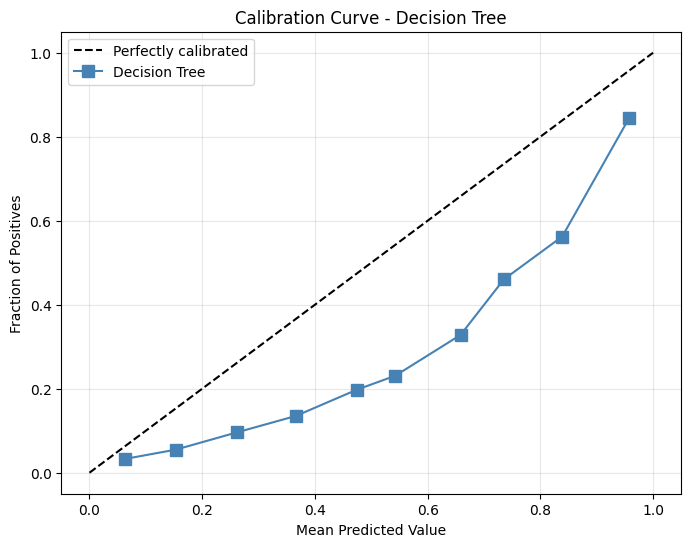

Calibration Curve saved.


In [56]:
# Calibration Curve
fop, mpv = calibration_curve(y_test, y_proba_best, n_bins=10, strategy='uniform')

fig = plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly calibrated', color='black')
plt.plot(mpv, fop, 's-', label='Decision Tree', color='steelblue', markersize=8)
plt.xlabel('Mean Predicted Value')
plt.ylabel('Fraction of Positives')
plt.title('Calibration Curve - Decision Tree')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
save_fig('dt_calibration_curve')
plt.show()

print("Calibration Curve saved.")

  [saved ../reports/figures/decision_tree/dt_precision_recall_curve.png]


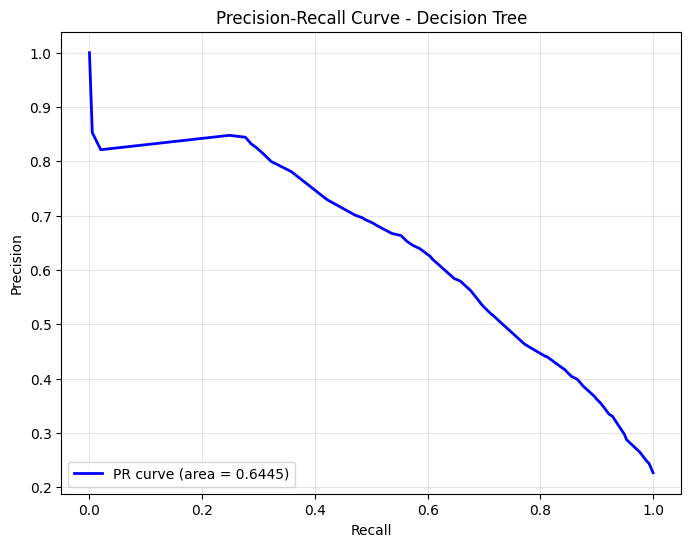

Precision-Recall Curve saved.


In [57]:
# Precision-Recall Curve
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_proba_best)
pr_auc = auc(recall_curve, precision_curve)

fig = plt.figure(figsize=(8, 6))
plt.plot(recall_curve, precision_curve, color='blue', lw=2, label=f'PR curve (area = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Decision Tree')
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)
save_fig('dt_precision_recall_curve')
plt.show()

print("Precision-Recall Curve saved.")

  [saved ../reports/figures/decision_tree/dt_roc_curve.png]


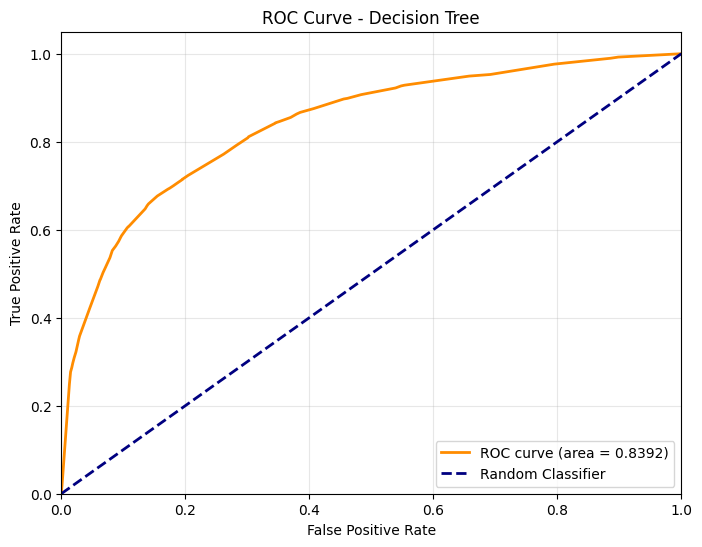

ROC Curve saved.


In [58]:
# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba_best)
roc_auc = auc(fpr, tpr)

fig = plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Decision Tree')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
save_fig('dt_roc_curve')
plt.show()

print("ROC Curve saved.")

  [saved ../reports/figures/decision_tree/dt_confusion_matrix.png]


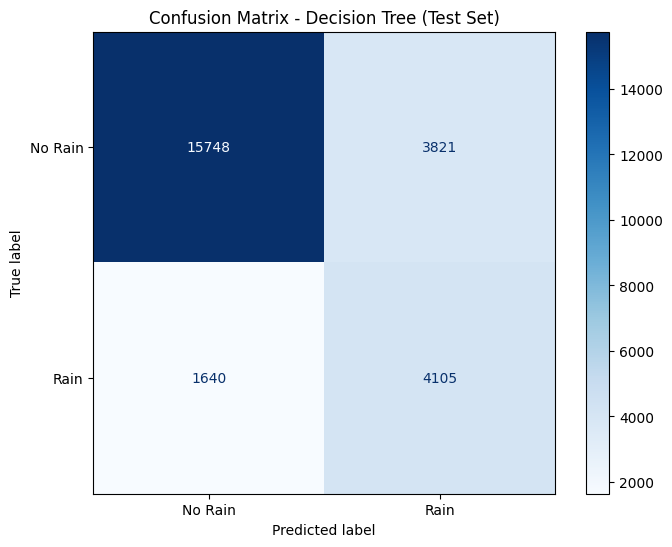

Confusion Matrix saved.


In [59]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_best, labels=[0, 1])
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Rain', 'Rain'])
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title('Confusion Matrix - Decision Tree (Test Set)')
save_fig('dt_confusion_matrix')
plt.show()

print("Confusion Matrix saved.")

### Decision Tree Visualization

Let's visualize the trained Decision Tree. Due to the potential complexity of the tree, only a portion might be clearly visible, but it will illustrate the decision-making process.

  [saved ../reports/figures/decision_tree/decision_tree_structure.png]


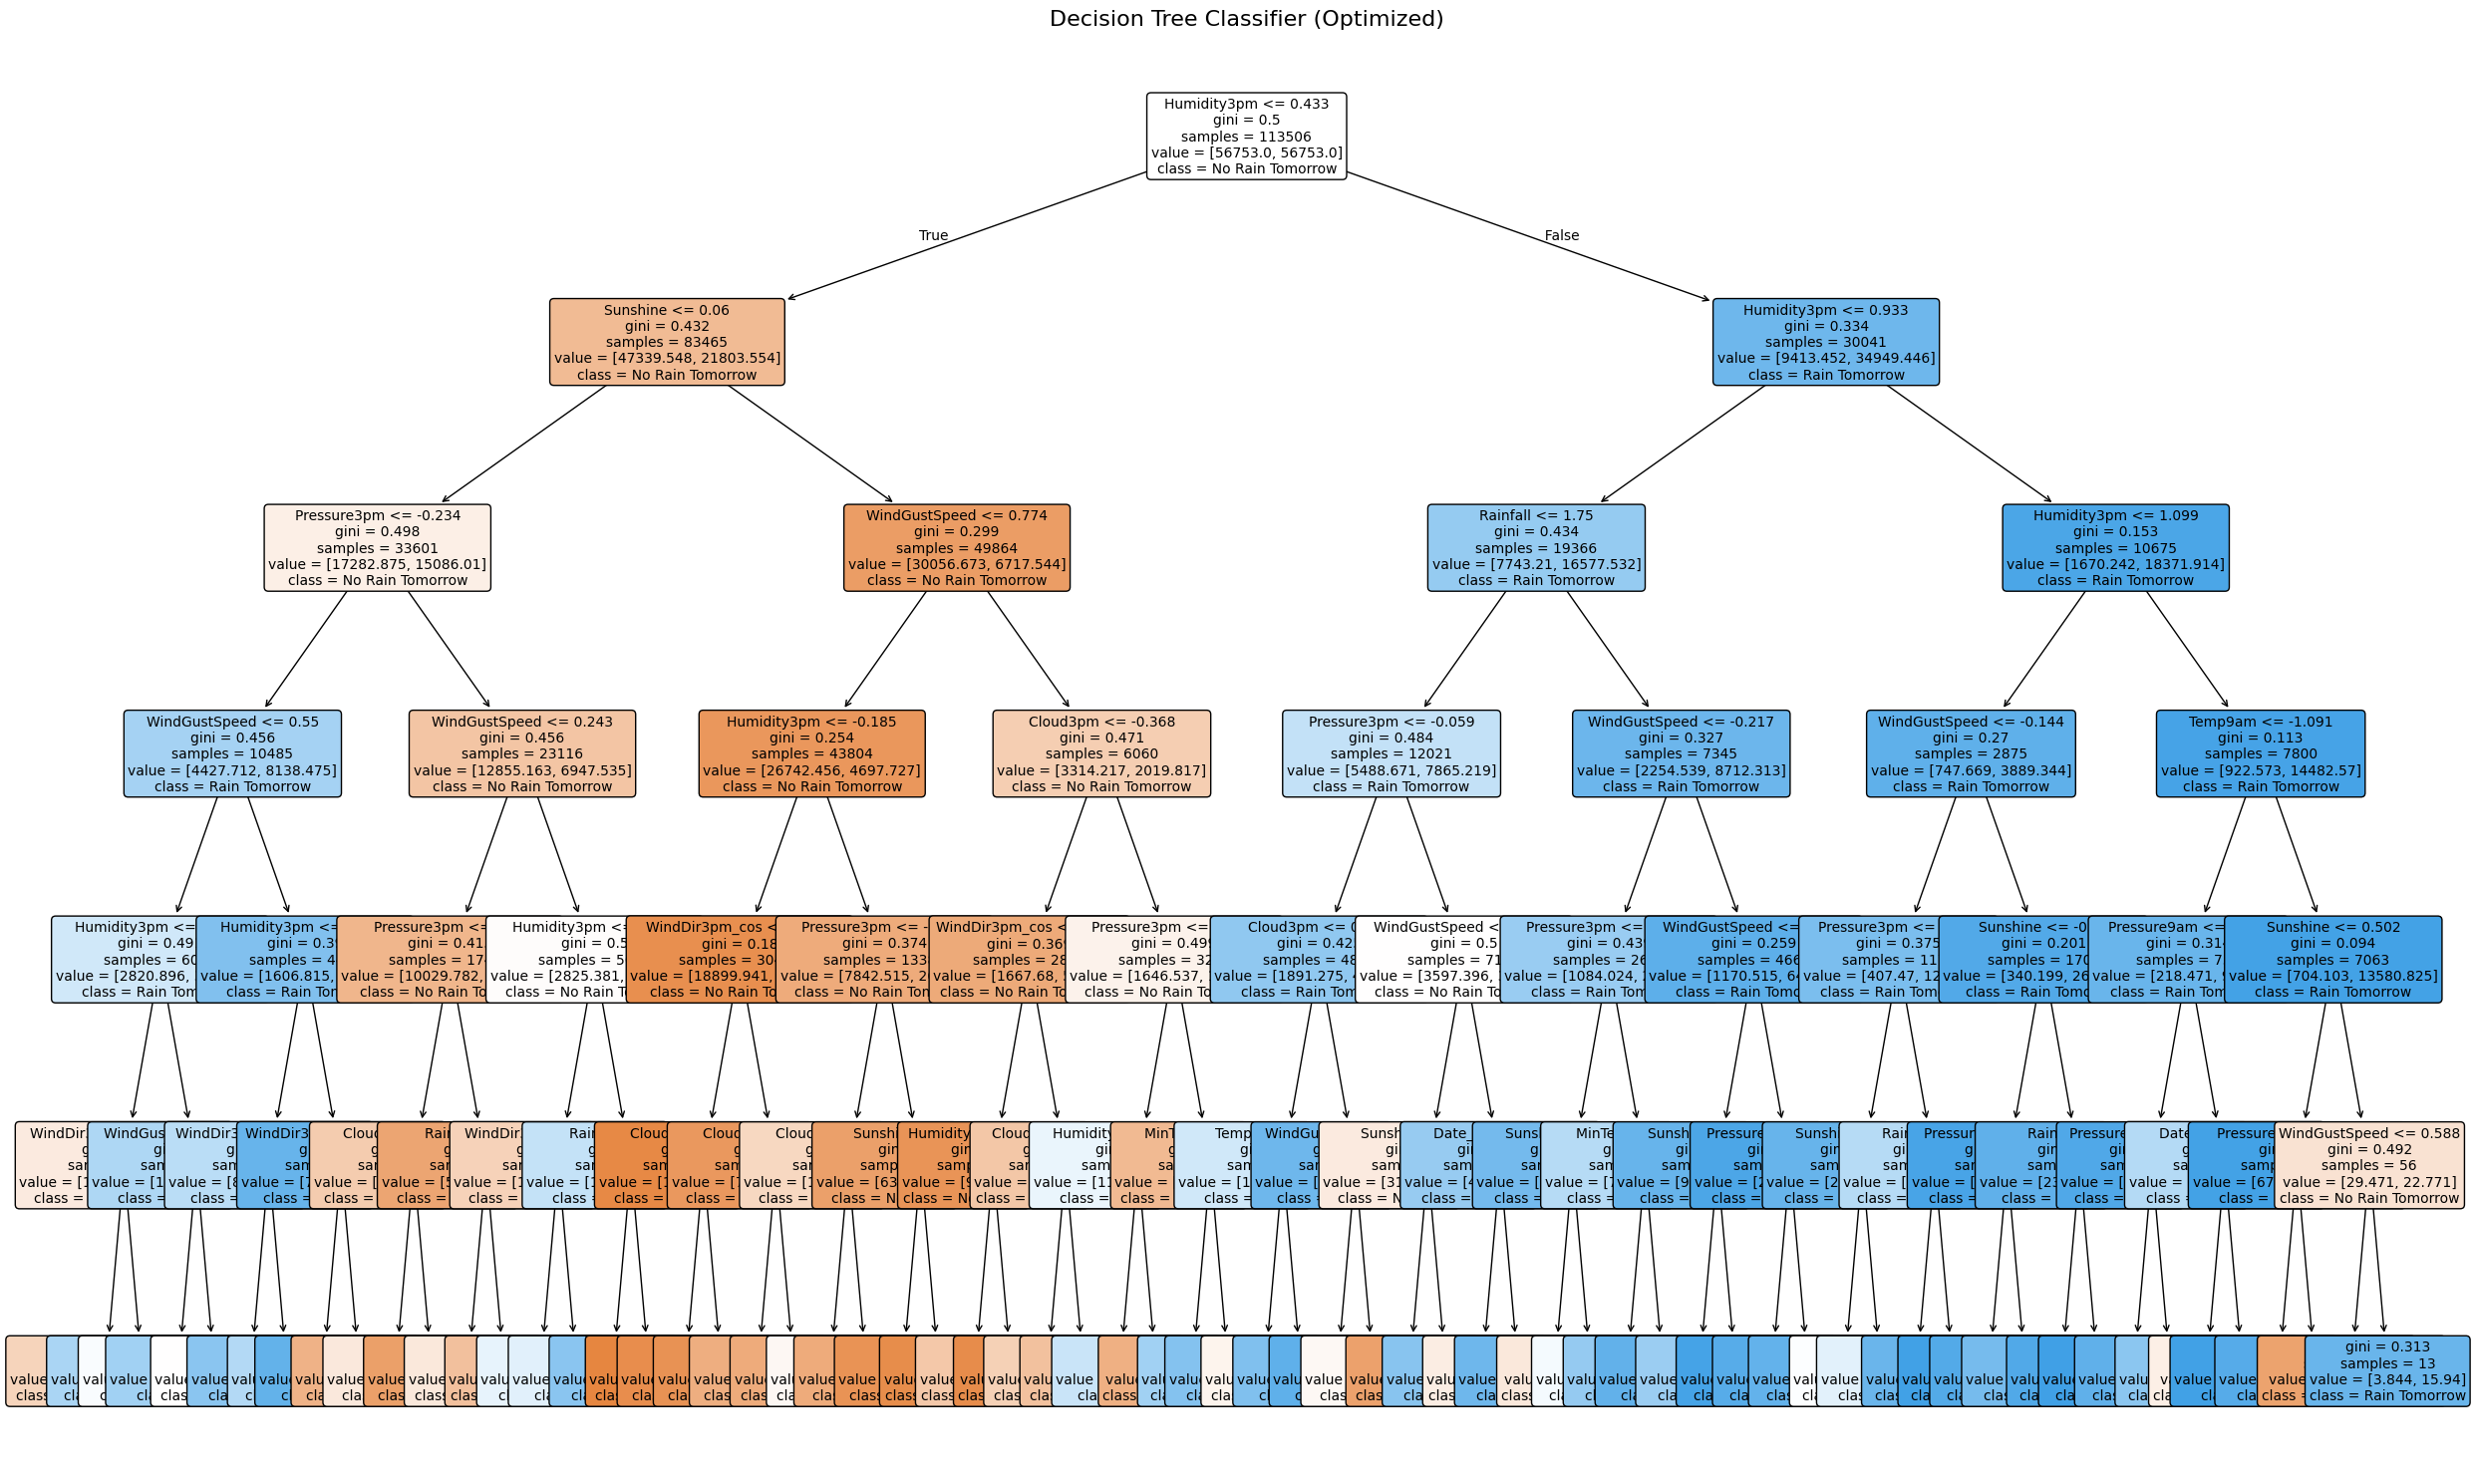

In [60]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Visualize the optimized decision tree
feature_names = X_train.columns.tolist()
class_names = ['No Rain Tomorrow', 'Rain Tomorrow']

plt.figure(figsize=(25, 15))
plot_tree(
    best_model,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Decision Tree Classifier (Optimized)', fontsize=16)
plt.tight_layout()
save_fig('decision_tree_structure')
plt.show()


In [61]:
feature_names = X_train.columns.tolist()

viz = dtreeviz.model(
    best_model,
    X_train=X_train.values,
    y_train=y_train.values,
    feature_names=feature_names,
    target_name='RainTomorrow',
    class_names=['No Rain', 'Rain']
)
v = viz.view()
v.save('../reports/figures/decision_tree/dtreeviz_structure.svg')
v

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X do

ExecutableNotFound: failed to execute 'dot', make sure the Graphviz executables are on your systems' PATH

La location ne rentre jamais dans le decision tree

In [ ]:
print("\n" + "=" * 70)
print("DECISION TREE CLASSIFIER - FINAL PERFORMANCE SUMMARY")
print("=" * 70)

# Compute all metrics for summary
precision_test = precision_score(y_test, y_pred_best)
recall_test = recall_score(y_test, y_pred_best)
f1_test = f1_score(y_test, y_pred_best)
roc_auc_test = auc_roc_best
log_loss_test = log_loss(y_test, y_proba_best)
brier_test = brier_score_loss(y_test, y_proba_best)

# Get Precision-Recall AUC
precision_test_pr, recall_test_pr, _ = precision_recall_curve(y_test, y_proba_best)
pr_auc_test = auc(recall_test_pr, precision_test_pr)

# Create summary DataFrame
summary_metrics = pd.DataFrame({
    'Metric': [
        'Precision (Rain)',
        'Recall (Rain)',
        'F1-Score (Rain)',
        'ROC-AUC',
        'PR-AUC',
        'Log Loss',
        'Brier Score'
    ],
    'Value': [
        f'{precision_test:.4f}',
        f'{recall_test:.4f}',
        f'{f1_test:.4f}',
        f'{roc_auc_test:.4f}',
        f'{pr_auc_test:.4f}',
        f'{log_loss_test:.4f}',
        f'{brier_test:.4f}'
    ]
})

print("\n📊 DECISION TREE CLASSIFIER - PERFORMANCE SUMMARY")
print(summary_metrics.to_string(index=False))
print("=" * 70)

# Best hyperparameters
print("\n🎯 Best Hyperparameters Found:")
print(f"   {best_params}")
print(f"   Best Cross-Validation ROC-AUC: {best_score:.4f}")

# Tree depth and complexity info
print(f"\n🌳 Model Complexity:")
print(f"   Tree Depth: {best_model.get_depth()}")
print(f"   Number of Leaves: {best_model.get_n_leaves()}")

# Save summary to CSV
# summary_metrics.to_csv('../reports/figures/decision_tree/metrics_summary.csv', index=False)
# print(f"\n✓ Metrics summary saved to: ../reports/figures/decision_tree/metrics_summary.csv")

# Save full report
report_dict = classification_report(y_test, y_pred_best, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
# report_df.to_csv('../reports/figures/decision_tree/classification_report.csv')
# print(f"✓ Classification report saved to: ../reports/figures/decision_tree/classification_report.csv")

# List all generated files
print("\n📁 Generated Files in ../reports/figures/decision_tree/:")
import glob
files = glob.glob('../reports/figures/decision_tree/*')
for f in sorted(files):
    print(f"   - {os.path.basename(f)}")

In [ ]:
print("\n" + "=" * 70)
print("DECISION TREE CLASSIFIER - FINAL PERFORMANCE SUMMARY (TRAIN)")
print("=" * 70)

# Predictions and probabilities on train set
y_pred_train = best_model.predict(X_train)
y_proba_train = best_model.predict_proba(X_train)[:, 1]

# Compute metrics for train summary
precision_train = precision_score(y_train, y_pred_train)
recall_train = recall_score(y_train, y_pred_train)
f1_train = f1_score(y_train, y_pred_train)
roc_auc_train = roc_auc_score(y_train, y_proba_train)
log_loss_train = log_loss(y_train, y_proba_train)
brier_train = brier_score_loss(y_train, y_proba_train)

# Get Precision-Recall AUC for train set
precision_train_pr, recall_train_pr, _ = precision_recall_curve(y_train, y_proba_train)
pr_auc_train = auc(recall_train_pr, precision_train_pr)

# Create summary DataFrame
summary_metrics_train = pd.DataFrame({
    'Metric': [
        'Precision (Rain)',
        'Recall (Rain)',
        'F1-Score (Rain)',
        'ROC-AUC',
        'PR-AUC',
        'Log Loss',
        'Brier Score'
    ],
    'Value': [
        f'{precision_train:.4f}',
        f'{recall_train:.4f}',
        f'{f1_train:.4f}',
        f'{roc_auc_train:.4f}',
        f'{pr_auc_train:.4f}',
        f'{log_loss_train:.4f}',
        f'{brier_train:.4f}'
    ]
})

print("\n📊 DECISION TREE CLASSIFIER - PERFORMANCE SUMMARY (TRAIN)")
print(summary_metrics_train.to_string(index=False))
print("=" * 70)

# Save summary to CSV
# summary_metrics_train.to_csv('../reports/figures/decision_tree/metrics_summary_train.csv', index=False)
# print(f"\n✓ Metrics summary saved to: ../reports/figures/decision_tree/metrics_summary_train.csv")

# Save full report for train set
report_dict_train = classification_report(y_train, y_pred_train, output_dict=True)
report_df_train = pd.DataFrame(report_dict_train).transpose()
# report_df_train.to_csv('../reports/figures/decision_tree/classification_report_train.csv')
# print(f"✓ Classification report saved to: ../reports/figures/decision_tree/classification_report_train.csv")

## Synthèse Finale - Decision Tree Classifier

Résumé complet des métriques et performances du Decision Tree Classifier optimisé